# Dron jako měřicí přístroj: časování, poloha a úhly na skutečném letu

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/drone_hardware_cs.ipynb)

**OpenSkyLab · notebook k laboratoři** [Dron jako měřicí přístroj](https://openskylab.space/edu_viz_drone_hardware.html) · [English version](drone_hardware_en.ipynb)

Laboratoř ukazuje, že dron je soustava přístrojů: přijímač GNSS, barometr, inerciální jednotka, gimbal a kamera, které měří každý trochu jinde a v trochu jiném okamžiku. Tady to ověříš na skutečném mapovacím letu nad Bahnami (DJI Mavic 2 Pro, bez RTK). Ke každému snímku máš polohu a výšky zapsané dronem, natočení těla a kamery a střed kamery spočtený z fotogrammetrie (SfM). Z jejich rozdílů zjistíš, jak rychle dron letěl, jak se naklání, o kolik se zpožďuje zápis polohy a jak moc se obraz rozmaže.

**Cíl:** z poloh a časů snímků určit řady, rychlost a rozestup snímků a najít chybějící snímky, porovnat náklon těla a kamery v řadách tam a zpět, oddělit zpoždění zápisu polohy od ramene páky antény, spočítat rozmazání pohybem a porovnat výšku z GNSS a z barometru.

**Data:** tabulka metadat 253 snímků letu nad Bahnami 31. 10. 2025 (EXIF a XMP od DJI) se středy kamer ze SfM, v místních souřadnicích (OpenSkyLab, CC BY 4.0).

**Úkoly:** pět. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 45 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

> **💻 Co dělá kód:** Nepovinná buňka. Když do ní vložíš nastavení zkopírované z laboratoře a spustíš ji, převezmou buňky níže stejné hodnoty parametrů a u každé to vypíšou. Když ji necháš prázdnou, použijí se výchozí hodnoty. Nic nestahuje.

In [1]:
#@title Nastavení z laboratoře (nepovinné)
#@markdown V laboratoři klikni na odkaz Notebook. Nastavení se zkopíruje; vlož ho sem místo `{}` (Ctrl+V) a buňku spusť.
Z_VIZUALU = {}  #@param {type:"raw"}
STEM = "drone_hardware"

def z_viz(name, default, mapping=None):
    """Hodnota parametru z laboratoře, pokud ji vložený kód obsahuje; jinak výchozí hodnota."""
    z = Z_VIZUALU if isinstance(Z_VIZUALU, dict) and Z_VIZUALU.get("osl") == STEM else {}
    if name not in z:
        return default
    v = z[name]
    if mapping is not None:
        if v not in mapping:
            print(f"{name}: hodnota {v!r} z laboratoře v tomto notebooku není, ponechávám {default!r}")
            return default
        v = mapping[v]
    elif isinstance(default, bool):
        v = bool(v)
    elif isinstance(default, int):
        v = int(round(v))
    elif isinstance(default, float):
        v = float(v)
    print(f"{name} = {v!r}  (z laboratoře)")
    return v

if isinstance(Z_VIZUALU, dict) and Z_VIZUALU and Z_VIZUALU.get("osl") != STEM:
    print(f"Vložený kód je z jiné laboratoře ({Z_VIZUALU.get('osl')}), notebook ho nepoužije.")

## 1. Data a trasa letu

Tabulka má jeden řádek na snímek. Polohy jsou v místní rovině v metrech (východ, sever), výšky nad místem vzletu. Mapovací let (`grid`) rozdělíme na řady podle skoků v poloze na sever a každé řadě určíme směr.

> **💻 Co dělá kód:** Stáhne z repozitáře notebooků tabulku metadat letu nad Bahnami (jeden řádek na snímek), vybere mapovací let, rozdělí ho na řady podle skoků v poloze na sever a každé řadě určí směr. Vypíše počty snímků a řad, délku letu a výšku a nakreslí trasu obarvenou směrem letu. Data jsou z OpenSkyLab pod licencí CC BY 4.0.

snímků: 253 (mapovací let 242, doplňkové 11), řad: 12
mapovací let trval 9.7 min, výška nad vzletem 100.0 m


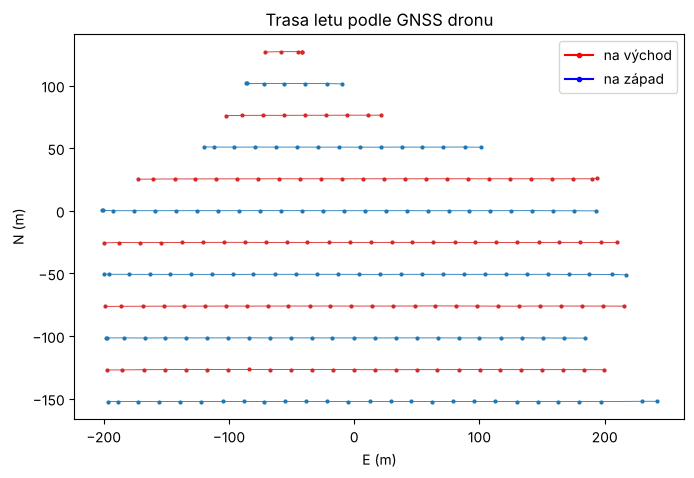

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

URL = "https://raw.githubusercontent.com/OpenSkyLab-space/notebooks/main/data/drone_hardware_bahna_flight.csv"
d = pd.read_csv(URL)
g = d[d.set == "grid"].sort_values("t_s").reset_index(drop=True)      # mapovací let v řadách
# nová řada začíná, když se poloha na sever skokem změní o víc než 5 m (rozestup řad je asi 25 m)
g["strip"] = (g.n_gnss.diff().abs() > 5).cumsum()
first, last = g.groupby("strip").e_gnss.first(), g.groupby("strip").e_gnss.last()
g["dir"] = g.strip.map(np.sign(last - first)).astype(int)              # +1 = na východ, −1 = na západ
print(f"snímků: {len(d)} (mapovací let {len(g)}, doplňkové {(d.set == 'extra').sum()}), řad: {g.strip.nunique()}")
print(f"mapovací let trval {g.t_s.max() / 60:.1f} min, výška nad vzletem {g.h_baro.median():.1f} m")
fig, ax = plt.subplots(figsize=(8, 5))
for s, q in g.groupby("strip"):
    ax.plot(q.e_gnss, q.n_gnss, ".-", ms=4, lw=.6, c="tab:red" if q.dir.iloc[0] > 0 else "tab:blue")
ax.plot([], [], "r.-", label="na východ"); ax.plot([], [], "b.-", label="na západ")
ax.set_aspect("equal"); ax.set_xlabel("E (m)"); ax.set_ylabel("N (m)"); ax.legend(); ax.set_title("Trasa letu podle GNSS dronu")
plt.show()

## 2. Rychlost, rozestup a chybějící snímky

Dron snímá v pravidelném intervalu. Rychlost v každé řadě je sklon přímky proložené polohou na východ v závislosti na čase. Čas je v EXIF jen na celé sekundy, proto přímka a ne rozdíly sousedních snímků.

> **💻 Co dělá kód:** Pro každou řadu spočte rychlost jako sklon přímky polohy na východ proti času, medián intervalu a rozestupu snímků a ukáže je jako tabulku. Pak najde chybějící čísla snímků a místa v řadách, kde je rozestup víc než 1,5× větší než obvykle.

In [3]:
rows = []
for s, q in g.groupby("strip"):
    v = abs(np.polyfit(q.t_s, q.e_gnss, 1)[0])                           # rychlost = sklon přímky E(t)
    rows.append({"řada": s, "směr": "E" if q.dir.iloc[0] > 0 else "W", "snímků": len(q),
                 "v (m/s)": round(v, 2), "interval (s)": q.t_s.diff().median(),
                 "rozestup (m)": round(np.hypot(q.e_gnss.diff(), q.n_gnss.diff()).median(), 1)})
st = pd.DataFrame(rows)
display(st)
V_DATA = st["v (m/s)"].median()
print(f"medián rychlosti {V_DATA:.2f} m/s")
num = g.image.str.extract(r"_(\d{4})", expand=False).astype(int)
missing = sorted(set(range(num.min(), num.max() + 1)) - set(num))
print(f"chybějící čísla snímků: {missing}")
step = np.hypot(g.e_gnss.diff(), g.n_gnss.diff())
same = g.strip.diff() == 0
big = g[same & (step > 1.5 * step[same].median())]
print("v řadě je rozestup větší než 1,5 × medián před snímky:", list(big.image))

,řada,směr,snímků,v (m/s),interval (s),rozestup (m)
0,0,W,27,8.32,2.0,16.7
1,1,E,25,8.31,2.0,16.7
2,2,W,25,8.26,2.0,16.7
3,3,E,26,8.35,2.0,16.8
4,4,W,27,8.29,2.0,16.7
5,5,E,26,8.34,2.0,16.7
6,6,W,26,8.15,2.0,16.7
7,7,E,24,8.27,2.0,16.7
8,8,W,15,8.08,2.0,16.7
9,9,E,9,8.03,2.0,16.7


medián rychlosti 8.27 m/s
chybějící čísla snímků: [3, 54, 55, 56, 57, 58, 59, 111, 165, 166]
v řadě je rozestup větší než 1,5 × medián před snímky: ['DJI_0004.JPG']


> **✏️ Úkol 1.** Jaká je rychlost, interval a rozestup snímků? Liší se řady na východ a na západ? Které snímky chybějí a dá se z rozestupů poznat, kde v řadě je díra?

*Tvoje odpověď:* 

## 3. Náklon těla a kamery

Multikoptéra letí dopředu tak, že se nakloní: tah rotorů pak má vodorovnou složku. Gimbal má náklon těla vyrovnat, aby kamera mířila kolmo dolů.

> **💻 Co dělá kód:** Spočte průměr a směrodatnou odchylku náklonu, klonění a kurzu těla dronu a náklonu a kurzu kamery zvlášť pro řady na východ a na západ. Vykreslí náklon těla a kamery a kurz těla v čase.

flight_pitch      flight_roll      flight_yaw      gimbal_pitch  \
                  mean  std        mean  std       mean  std         mean   
dir                                                                         
na západ           8.2  8.1         1.5  3.0       90.1  0.3        -90.0   
na východ         -9.4  7.2         1.9  1.1       90.0  2.2        -90.0   

               gimbal_yaw       
           std       mean  std  
dir                             
na západ   0.1       92.0  0.0  
na východ  0.0       92.0  0.0

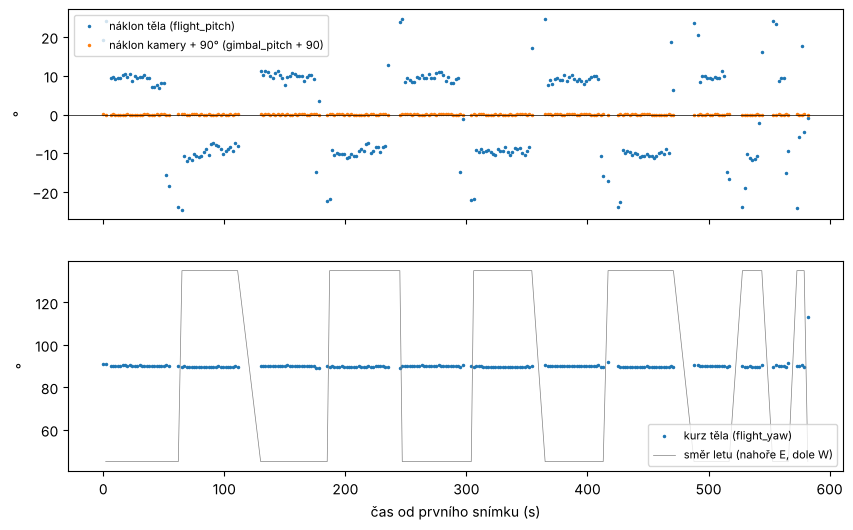

In [4]:
att = g.groupby("dir")[["flight_pitch", "flight_roll", "flight_yaw", "gimbal_pitch", "gimbal_yaw"]].agg(["mean", "std"]).round(1)
att.index = att.index.map({1: "na východ", -1: "na západ"})
display(att)
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(g.t_s, g.flight_pitch, ".", ms=3, label="náklon těla (flight_pitch)")
ax[0].plot(g.t_s, g.gimbal_pitch + 90, ".", ms=3, label="náklon kamery + 90° (gimbal_pitch + 90)")
ax[0].axhline(0, c="k", lw=.5); ax[0].set_ylabel("°"); ax[0].legend(fontsize=8)
ax[1].plot(g.t_s, g.flight_yaw, ".", ms=3, label="kurz těla (flight_yaw)")
ax[1].plot(g.t_s, g.e_gnss.diff().apply(np.sign) * 45 + 90, "-", lw=.5, c="gray", label="směr letu (nahoře E, dole W)")
ax[1].set_ylabel("°"); ax[1].set_xlabel("čas od prvního snímku (s)"); ax[1].legend(fontsize=8)
plt.show()

> **✏️ Úkol 2.** Kam míří nos dronu v řadách na východ a na západ? Jaký je náklon těla v obou směrech a proč má opačné znaménko? Udržel gimbal kameru kolmo dolů? Proč náklon na východ a na západ není stejně velký?

*Tvoje odpověď:* 

## 4. Zpoždění zápisu polohy a rameno páky

Střed kamery ze SfM je určený ze snímků, poloha v EXIF z GNSS. Když se poloha zapíše o dt později než expozice, je posunutá o v · dt ve směru letu, takže v řadách tam a zpět má opačné znaménko. Anténa posunutá vůči kameře (rameno páky) dá posun, který se se směrem letu nemění, protože nos dronu míří stále stejně. Pozor: SfM bylo na polohy GNSS přiloženo podobnostní transformací, takže stálý posun celého bloku tím zmizel a z dat ho určit nejde.

> **💻 Co dělá kód:** Převezme rychlost, zpoždění a rameno páky z laboratoře (nebo výchozí hodnoty), spočte rozdíl polohy GNSS a středu kamery ze SfM a jeho průměr v řadách na východ a na západ. Z poloviny rozdílu obou průměrů odhadne posun v · dt a zpoždění dt, z jejich průměru stálý posun a porovná je s laboratoří. Spočte i posun antény náklonem těla a nakreslí histogramy rozdílů.

dE               dN           
           mean   std size  mean   std size
dir                                        
na západ  -1.82  0.97  127 -0.14  0.60  127
na východ  2.01  0.89  115  0.15  0.63  115

posun ve směru letu v·dt = 1.92 m  →  dt = 0.232 s při v = 8.27 m/s
laboratoř: v·dt = 1.92 m (v = 8.0 m/s, dt = 0.24 s)
stálý posun na východ: +0.09 m
laboratoř: anténa 0.00 m před kamerou by dala stálý posun +0.00 m na východ (nos míří na východ)
posun antény náklonem těla (lever_z · sin|pitch|): 0.031 m


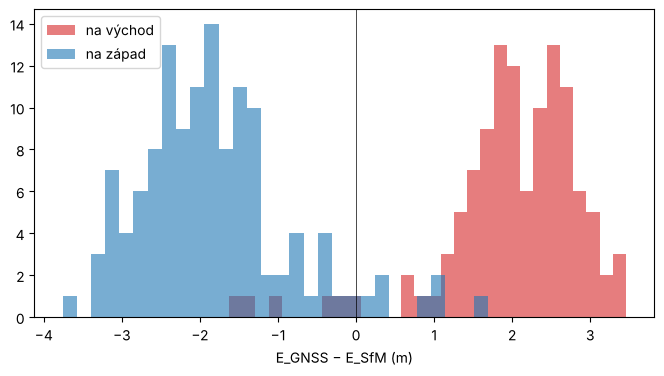

In [5]:
SPEED = z_viz("speed", 8.0)        # ◀ parametr: rychlost letu v laboratoři (m/s)
DT = z_viz("dt", 0.24)             # ◀ parametr: zpoždění zápisu polohy v laboratoři (s)
LEVER_X = z_viz("lever_x", 0.0)    # ◀ parametr: anténa před kamerou v laboratoři (m)
LEVER_Z = z_viz("lever_z", 0.2)    # ◀ parametr: anténa nad kamerou v laboratoři (m)
ok = g.e_sfm.notna()
g["dE"] = g.e_gnss - g.e_sfm                                             # GNSS minus střed kamery ze SfM, východ
g["dN"] = g.n_gnss - g.n_sfm
m = g[ok].groupby("dir")[["dE", "dN"]].agg(["mean", "std", "size"]).round(2)
m.index = m.index.map({1: "na východ", -1: "na západ"})
display(m)
dE_e, dE_w = g[ok & (g.dir > 0)].dE.mean(), g[ok & (g.dir < 0)].dE.mean()
# model: dE = směr · v · dt + stálý posun (rameno páky; nos dronu míří stále na východ)
vdt = (dE_e - dE_w) / 2
const = (dE_e + dE_w) / 2
print(f"posun ve směru letu v·dt = {vdt:.2f} m  →  dt = {vdt / V_DATA:.3f} s při v = {V_DATA:.2f} m/s")
print(f"laboratoř: v·dt = {SPEED * DT:.2f} m (v = {SPEED} m/s, dt = {DT} s)")
print(f"stálý posun na východ: {const:+.2f} m")
print(f"laboratoř: anténa {LEVER_X:.2f} m před kamerou by dala stálý posun {LEVER_X:+.2f} m na východ (nos míří na východ)")
tilt = LEVER_Z * np.sin(np.radians(g.groupby("dir").flight_pitch.mean().abs().mean()))
print(f"posun antény náklonem těla (lever_z · sin|pitch|): {tilt:.3f} m")
fig, ax = plt.subplots(figsize=(8, 4))
for s_, c, lab in ((1, "tab:red", "na východ"), (-1, "tab:blue", "na západ")):
    ax.hist(g[ok & (g.dir == s_)].dE, bins=30, alpha=.6, color=c, label=lab)
ax.axvline(0, c="k", lw=.5); ax.set_xlabel("E_GNSS − E_SfM (m)"); ax.legend(); plt.show()

> **✏️ Úkol 3.** Jaké zpoždění dt vychází z dat a jak se shoduje s laboratoří? Proč stálý posun vychází skoro nulový, i kdyby anténa byla před kamerou? Jak velký posun způsobí náklon těla s anténou 0,2 m nad kamerou a dá se odlišit od zpoždění?

*Tvoje odpověď:* 

## 5. Rozmazání pohybem a závěrka

Během expozice se dron posune o v · t_exp. Když je to víc než asi polovina pixelu na zemi (GSD), snímek se viditelně rozmaže. Kamera L1D-20c nemá mechanickou závěrku: čip se vyčítá po řádcích (rolling shutter) a během vyčtení se dron posune o v · t_read.

> **💻 Co dělá kód:** Z výšky, ohniska a velikosti pixelu spočte GSD, z rychlosti řady a expozičního času rozmazání v centimetrech a pixelech a ukáže je podle expozičního času. Pro porovnání vypíše rozmazání pro expoziční čas z laboratoře a posun během vyčtení čipu `T_READ`.

In [6]:
F_MM, PIX_UM = 10.26, 2.41        # ohnisko a velikost pixelu Hasselblad L1D-20c (EXIF snímků: f = 10,26 mm, ekvivalent 28 mm, 5472 px)
T_EXP = z_viz("t_exp", 0.002)      # ◀ parametr: expoziční čas v laboratoři (s)
T_READ = z_viz("t_read", 0.03)     # ◀ parametr: doba vyčtení čipu v laboratoři (s), 0 = mechanická závěrka
g["gsd_cm"] = g.h_baro * PIX_UM * 1e-6 / (F_MM * 1e-3) * 100
g["v"] = g.strip.map(dict(zip(st.iloc[:, 0], st["v (m/s)"])))
g["blur_cm"] = g.v * g.exposure_s * 100
g["blur_px"] = g.blur_cm / g.gsd_cm
tab = g.groupby("exposure_s").agg(n=("image", "size"), gsd_cm=("gsd_cm", "median"), blur_cm=("blur_cm", "median"), blur_px=("blur_px", "median")).round(2)
tab.index = [f"1/{1 / e:.0f} s" for e in tab.index]
display(tab)
print(f"laboratoř: t_exp = 1/{1 / T_EXP:.0f} s → rozmazání {SPEED * T_EXP * 100:.1f} cm = {SPEED * T_EXP * 100 / g.gsd_cm.median():.2f} px")
print(f"posun během vyčtení čipu (t_read = {T_READ} s): {V_DATA * T_READ * 100:.0f} cm = {V_DATA * T_READ * 100 / g.gsd_cm.median():.0f} px mezi první a poslední řádkou snímku")

,n,gsd_cm,blur_cm,blur_px
1/200 s,65,2.35,4.08,1.73
1/160 s,112,2.35,5.18,2.21
1/120 s,65,2.35,6.92,2.95


laboratoř: t_exp = 1/500 s → rozmazání 1.6 cm = 0.68 px
posun během vyčtení čipu (t_read = 0.03 s): 25 cm = 11 px mezi první a poslední řádkou snímku


> **✏️ Úkol 4.** Jaké expoziční časy kamera použila a jak velké je rozmazání v pixelech? Jaký nejdelší čas by při této rychlosti a výšce dal rozmazání pod 0,5 px? Co bys změnil v plánu letu, kdyby bylo pod mrakem tmavěji?

*Tvoje odpověď:* 

## 6. Výška z GNSS a z barometru

Dron měří výšku barometrem (rozdíl tlaku proti místu vzletu) a přijímačem GNSS. `h_gnss` je absolutní výška z XMP posunutá tak, aby šla porovnat s `h_baro`.

> **💻 Co dělá kód:** Spočte rozdíl výšky z GNSS a z barometru, jeho průměr, rozptyl, rozsah a trend v čase a rozptyl rozdílu proti výšce ze SfM. Vykreslí všechny tři výšky v čase.

h_gnss − h_baro: průměr +0.06 m, směrodatná odchylka 0.88 m, rozsah -1.99 … +1.83 m
trend h_gnss − h_baro: -0.268 m/min
h_sfm − h_baro: směrodatná odchylka 2.11 m;  h_sfm − h_gnss: 2.28 m


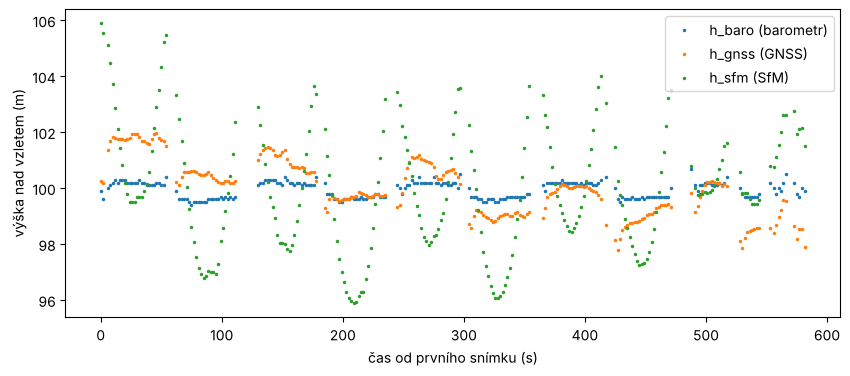

In [7]:
g["dh"] = g.h_gnss - g.h_baro
print(f"h_gnss − h_baro: průměr {g.dh.mean():+.2f} m, směrodatná odchylka {g.dh.std():.2f} m, rozsah {g.dh.min():+.2f} … {g.dh.max():+.2f} m")
k = np.polyfit(g.t_s, g.dh, 1)[0] * 60
print(f"trend h_gnss − h_baro: {k:+.3f} m/min")
okh = g.h_sfm.notna()
print(f"h_sfm − h_baro: směrodatná odchylka {(g.h_sfm - g.h_baro)[okh].std():.2f} m;  h_sfm − h_gnss: {(g.h_sfm - g.h_gnss)[okh].std():.2f} m")
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(g.t_s, g.h_baro, ".", ms=3, label="h_baro (barometr)")
ax.plot(g.t_s, g.h_gnss, ".", ms=3, label="h_gnss (GNSS)")
ax.plot(g.t_s[okh], g.h_sfm[okh], ".", ms=3, label="h_sfm (SfM)")
ax.set_xlabel("čas od prvního snímku (s)"); ax.set_ylabel("výška nad vzletem (m)"); ax.legend()
plt.show()

> **✏️ Úkol 5.** Který senzor drží výšku stabilněji a proč? Má rozdíl h_gnss − h_baro trend v čase? Čím se může barometr během letu posunout?

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Doplňkové snímky (`set == 'extra'`) mají jiný náklon kamery a výšku. Které z nich se v SfM neregistrovaly a proč?

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Data letu: OpenSkyLab (2026), metadata letu Bahna 31. 10. 2025 odvozená ze snímků a z rekonstrukce SfM, licence CC BY 4.0, https://github.com/OpenSkyLab-space/notebooks/tree/main/data
- Pix4D: *How to correct for the rolling shutter effect* a *Time offset between GNSS and camera* (dokumentace Pix4Dmapper).
- Vautherin, J., Rutishauser, S., Schneider-Zapp, K., Choi, H. F., Chovancova, V., Glass, A., Strecha, C. (2016). Photogrammetric accuracy and modeling of rolling shutter cameras. *ISPRS Annals* III-3, 139–146.
- Groves, P. D. (2013). *Principles of GNSS, Inertial, and Multisensor Integrated Navigation Systems*, 2. vyd. Artech House (rameno páky, synchronizace senzorů).

### Jak citovat

OpenSkyLab (2026). Dron jako měřicí přístroj: časování, poloha a úhly na skutečném letu [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/drone_hardware_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*